In [ ]:
'''
hopefully we will find the signal to noise ratio here
'''

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

In [2]:
import plot_time_series as pts
import precision_recall as pr
import importlib
#importlib.reload(plot_time_series)
import gc #garbage collector
import glob #i don't know if there is a better way to do this but this was the 
#internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from scipy.signal import find_peaks

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [15]:
def add_snr(df, direcname, half_aperture, tracking):
    '''
    returns the dataframe with a new column of stdv ratios 
    see get_sobel_ratio(stamp) and get_stdv_ratio
    '''
    ratios_center = np.zeros(len(df))
    ratios_max = np.zeros(len(df))
    ratios_min = np.zeros(len(df))
    for index in df.index:
        # print(index)
        tot, maxcols = rff.get_tot(df, index, direcname, half_aperture, tracking)
        stdv = rff.get_stdvs(tot, do_all=False, df=df, index=index)
        avg = np.average(tot)
        row = int(df.loc[index]["row_from_nn"])+10
        max_val = np.max(tot[row-10:row+10])
        min_val = np.min(tot[row-10:row+10])
        signal_center = tot[row] - avg
        signal_max = max_val - avg
        signal_min = min_val - avg
        ratios_center[index] = signal_center/stdv
        ratios_max[index] = signal_max/stdv
        ratios_min[index] = signal_min/stdv
    df["snr_center"] = ratios_center
    df["snr_max"] = ratios_max
    df["snr_min"] = ratios_min
    return df

In [7]:
#okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = '/lustre/lrspec/ZTF_data/science_extractions/1020'
direcname = '1020'
fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"


# List all the files in the folder
files = [f for f in os.listdir(folder_path) if f.endswith('snr')]  # Adjust this to your file format




    
# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for number, f in enumerate(files):
    
    dpath = os.path.join(folder_path, f + '_snr')
    
    # # Skip if the reduced file already exists
    # if os.path.isfile(dpath) and number>6:
    #     print('i should skip this one: ', f)
    #     continue
        
    # print('working on now: ', f)
    
    df = pd.read_csv(os.path.join(folder_path, f))
    # nocrs = df[df['sobel_ratio']>5]
    # df_new = add_snr(nocrs, direcname, half_aperture=2, tracking=True)
    # df_new.to_csv(dpath)
    dataframes.append(df)

# # Step 4: Concatenate all DataFrames into one
concatenated_df_snr = pd.concat(dataframes, ignore_index=True)

# # Display the concatenated DataFrame
concatenated_df_snr

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,0,3,3,ztf_20221020297847_000449_zr_c05_x_0006.,pos,627.166667,559.333333,6.0,4,12.891250,1.303873,1.792471,-1.921662
1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8.0,4,12.620198,3.551599,3.661652,-3.093721
2,2,2,8,8,ztf_20221020297847_000449_zr_c05_x_0006.,pos,1834.833333,560.916667,12.0,4,7.786941,2.971391,2.971391,-1.201024
3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12.0,4,9.809223,3.095683,3.140310,-0.995967
4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,14.0,4,12.620198,-1.530615,3.552551,-3.001541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610898,263,263,551,551,ztf_20221020297847_000449_zr_c14_x_0026.,both,2923.142857,1320.428571,7.0,4,9.755448,0.476716,1.637385,-1.839140
610899,264,264,552,552,ztf_20221020297847_000449_zr_c14_x_0026.,both,2937.153846,1320.692308,13.0,4,11.997117,0.194553,0.760646,-1.656184
610900,265,265,554,554,ztf_20221020297847_000449_zr_c14_x_0026.,both,2951.500000,1321.416667,12.0,4,14.919274,-0.671413,0.720585,-1.495678
610901,266,266,555,555,ztf_20221020297847_000449_zr_c14_x_0026.,both,2952.000000,1326.000000,9.0,4,14.998910,-1.493181,0.719382,-1.493181


In [20]:
# f = 'ztf_20221020154120_000640_zi_c09_x_0017.fits.fz4alllist_reduced_sobelratio_snr'
# test =  pd.read_csv(os.path.join(folder_path, f))

In [ ]:
#so let's first get the light curve
#easy to compute the average
#we will test with the saved center
#mm we have the size saved...i guess we can assume they're spherical and check for the minimum

In [6]:
rff.get_tot?

Signature: rff.get_tot(df, index, direcname, half_aperture, tracking=True)
Docstring:
returns tot, maxcols: an array that is the flux of the star streak
given an aperture that is halfaperture*2+1
and if tracking=true, tracks when the streak posittion fluctuates
oif tracking==false, goes based on average center of streak
File:      ~/review_findings_functions.py
Type:      function

(array([1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05, 1.e+06,
        1.e+07, 1.e+08]),
 [Text(0, 0.1, '$\\mathdefault{10^{-1}}$'),
  Text(0, 1.0, '$\\mathdefault{10^{0}}$'),
  Text(0, 10.0, '$\\mathdefault{10^{1}}$'),
  Text(0, 100.0, '$\\mathdefault{10^{2}}$'),
  Text(0, 1000.0, '$\\mathdefault{10^{3}}$'),
  Text(0, 10000.0, '$\\mathdefault{10^{4}}$'),
  Text(0, 100000.0, '$\\mathdefault{10^{5}}$'),
  Text(0, 1000000.0, '$\\mathdefault{10^{6}}$'),
  Text(0, 10000000.0, '$\\mathdefault{10^{7}}$'),
  Text(0, 100000000.0, '$\\mathdefault{10^{8}}$')])

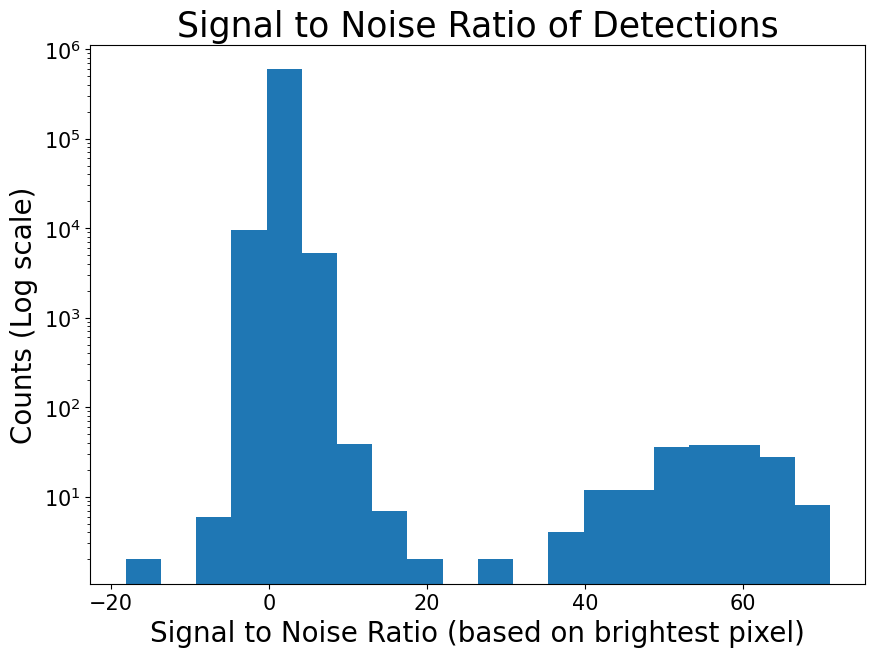

In [5]:
plt.hist(concatenated_df_snr['snr_max'], bins=20)
plt.yscale('log')
plt.title('Signal to Noise Ratio of Detections', fontsize=25)
plt.ylabel('Counts (Log scale)', fontsize=20)
plt.xlabel("Signal to Noise Ratio (based on brightest pixel)", fontsize=20)
# plt.xlim(0,20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

In [38]:
df_toobig = concatenated_df_snr[concatenated_df_snr['snr_max']>25]

In [39]:
df_toobig[df_toobig['snr_max']<40]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
28614,14,14,55,55,ztf_20221020141806_000686_zi_c15_x_0009.,neg,2401.5,2194.0,6.0,3,11.904259,27.410943,28.334518,-3.239271
28629,29,29,113,113,ztf_20221020141806_000686_zi_c15_x_0009.,both,2401.5,2194.0,6.0,3,11.904259,27.410943,28.334518,-3.239271
121986,72,72,674,674,ztf_20221020138241_000686_zi_c16_x_0026.,neg,1218.0,2486.0,5.0,3,16.478485,38.010690,38.956832,37.412383
121987,73,73,677,677,ztf_20221020138241_000686_zi_c16_x_0026.,neg,1303.0,2491.0,5.0,3,16.925287,35.014644,35.940121,34.159991
122066,153,153,1075,1075,ztf_20221020138241_000686_zi_c16_x_0026.,both,1218.0,2486.0,5.0,3,16.478485,38.010690,38.956832,37.412383
122067,154,154,1087,1087,ztf_20221020138241_000686_zi_c16_x_0026.,both,1303.0,2491.0,5.0,3,16.925287,35.014644,35.940121,34.159991


In [114]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

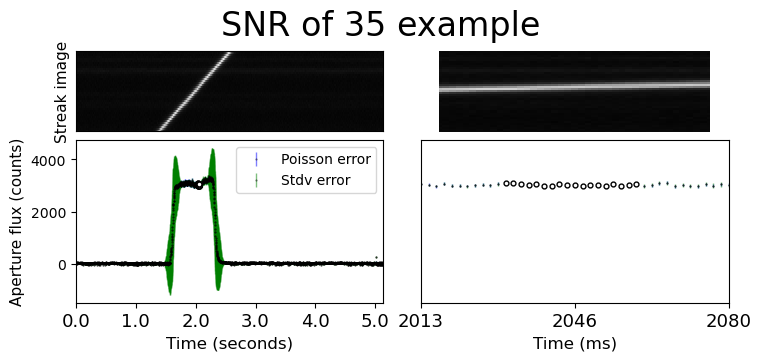

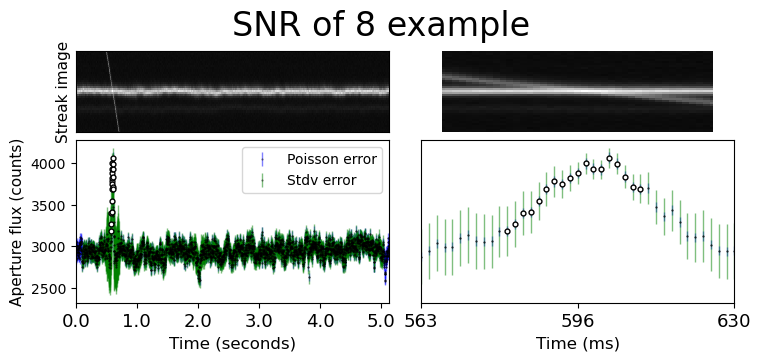

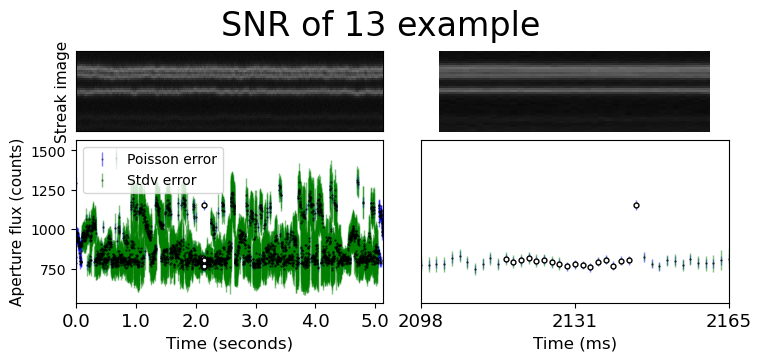

In [119]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 121986, '1020', 2, True, title="SNR of 35 example")
rff.plot_time_series_again_aperture(concatenated_df_snr, 132762, '1020', 2, True, title="SNR of 8 example")
rff.plot_time_series_again_aperture(concatenated_df_snr, 50286, '1020', 2, True, title="SNR of 13 example")

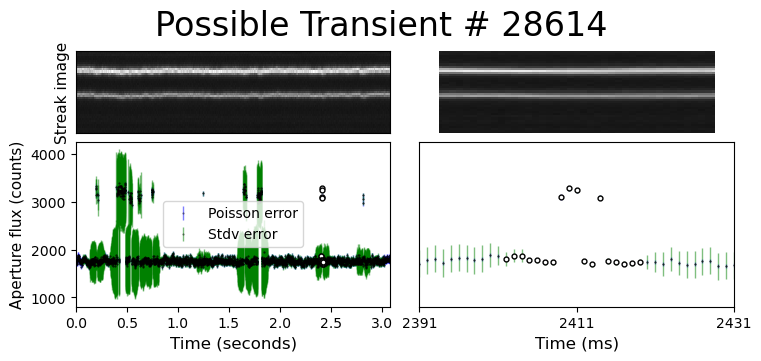

/home/3155/review_findings_functions.py:1137: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


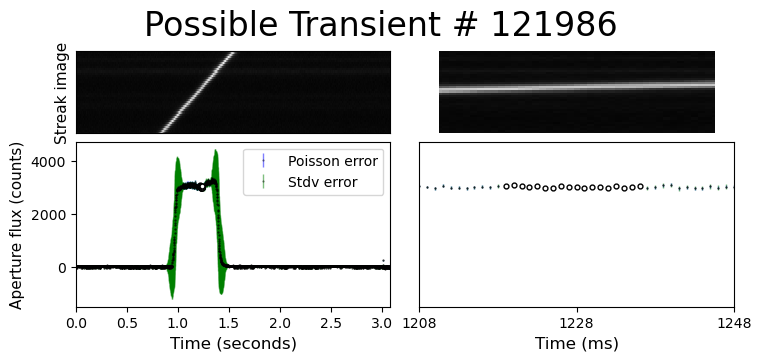

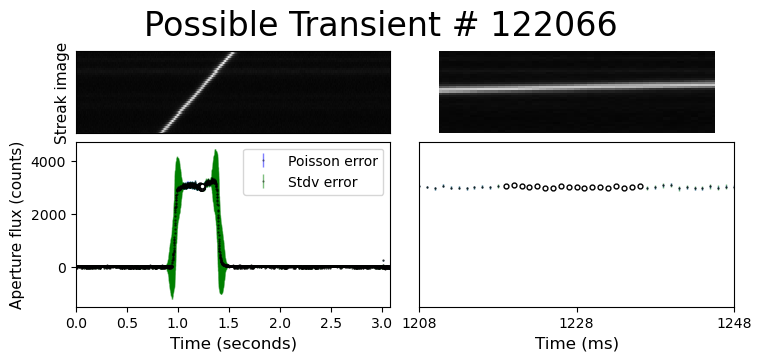

In [41]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 28614, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 121986, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 122066, '1020', 2, True)

In [43]:
df_smallenough = concatenated_df_snr[concatenated_df_snr['snr_max']<25]

In [53]:
df_smallenough[df_smallenough['snr_max']>8]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
8859,49,49,116,116,ztf_20221020148032_000686_zg_c16_x_0014.,pos,1397.954454,772.878098,1493.0,4,5.886429,9.630143,10.074712,9.143934
8870,60,60,158,158,ztf_20221020148032_000686_zg_c16_x_0014.,pos,1426.857143,771.857143,7.0,4,5.103120,9.458409,9.592639,8.773488
8920,110,110,302,302,ztf_20221020148032_000686_zg_c16_x_0014.,pos,2884.410695,514.209626,935.0,4,6.324615,16.718662,17.563966,15.719151
8926,116,116,321,321,ztf_20221020148032_000686_zg_c16_x_0014.,pos,2892.500000,516.833333,6.0,4,5.742915,9.451835,9.613728,8.622006
9353,543,543,1146,1146,ztf_20221020148032_000686_zg_c16_x_0014.,both,1397.954454,772.878098,1493.0,4,5.886429,9.630143,10.074712,9.143934
9388,578,578,1230,1230,ztf_20221020148032_000686_zg_c16_x_0014.,both,1426.857143,771.857143,7.0,4,5.103120,9.458409,9.592639,8.773488
9542,732,732,1552,1552,ztf_20221020148032_000686_zg_c16_x_0014.,both,2884.410695,514.209626,935.0,4,6.324615,16.718662,17.563966,15.719151
9561,751,751,1600,1600,ztf_20221020148032_000686_zg_c16_x_0014.,both,2892.500000,516.833333,6.0,4,5.742915,9.451835,9.613728,8.622006
50286,63,63,219,219,ztf_20221020163819_000640_zg_c12_x_0014.,neg,1269.600000,1846.800000,5.0,1,11.123486,-6.020797,13.057268,-6.898950
50390,167,167,554,554,ztf_20221020163819_000640_zg_c12_x_0014.,both,1269.600000,1846.800000,5.0,1,11.123486,-6.020797,13.057268,-6.898950


/home/3155/review_findings_functions.py:1137: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


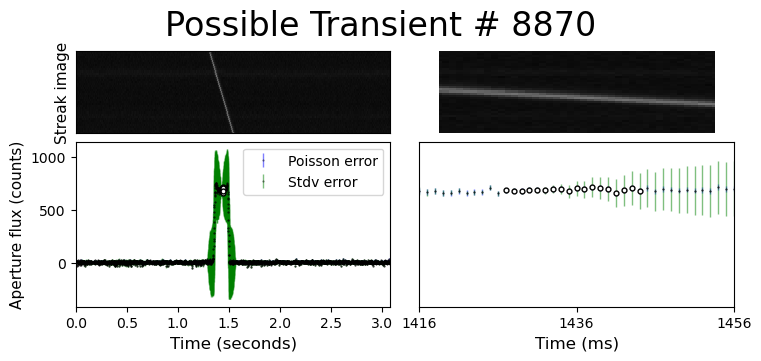

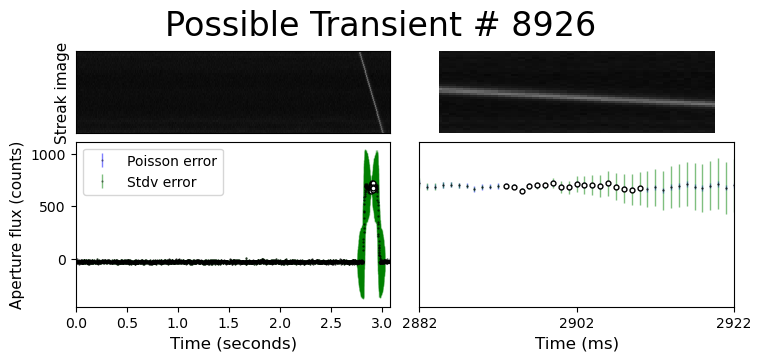

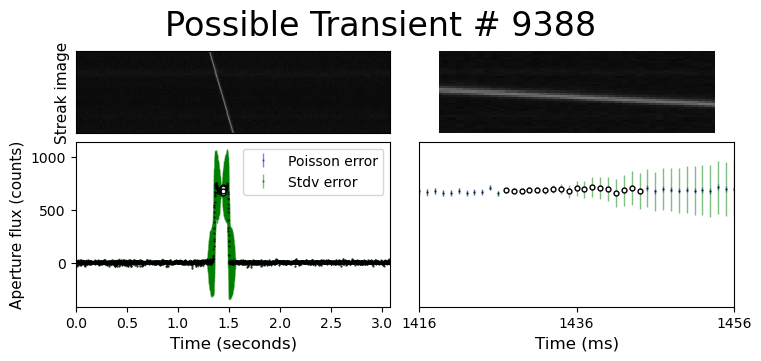

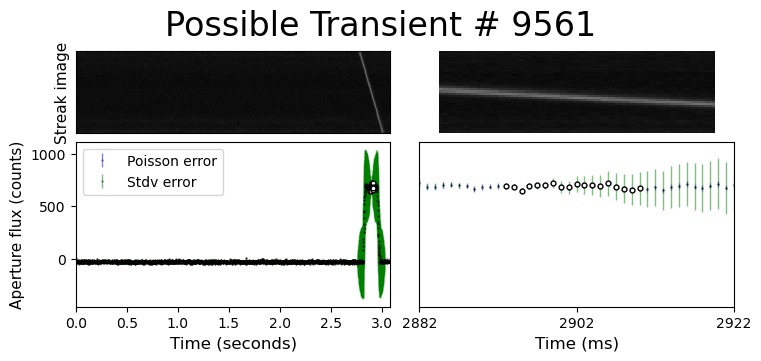

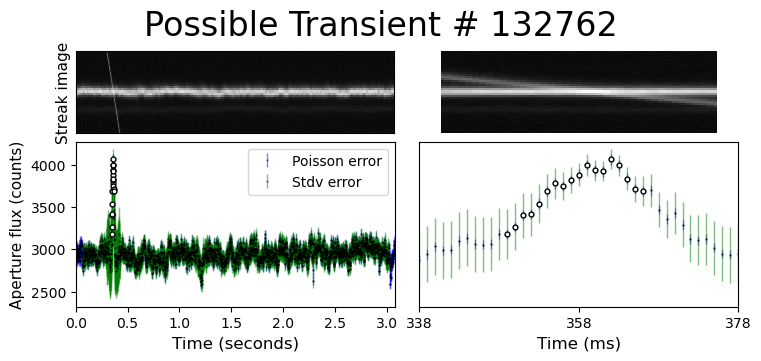

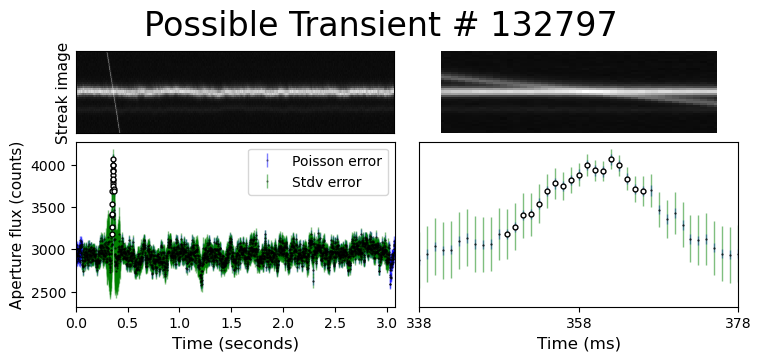

In [54]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 8870, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 8926, '1020', 2, True)

rff.plot_time_series_again_aperture(concatenated_df_snr, 9388, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 9561, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 132762, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 132797, '1020', 2, True)

/home/3155/review_findings_functions.py:1137: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


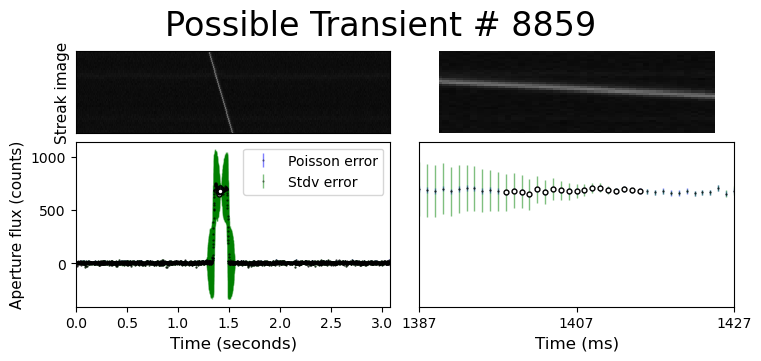

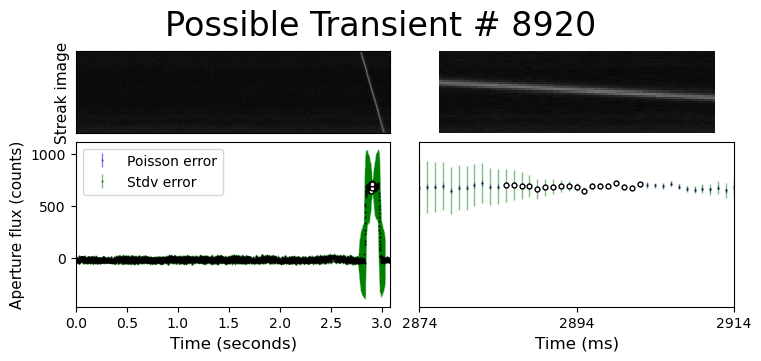

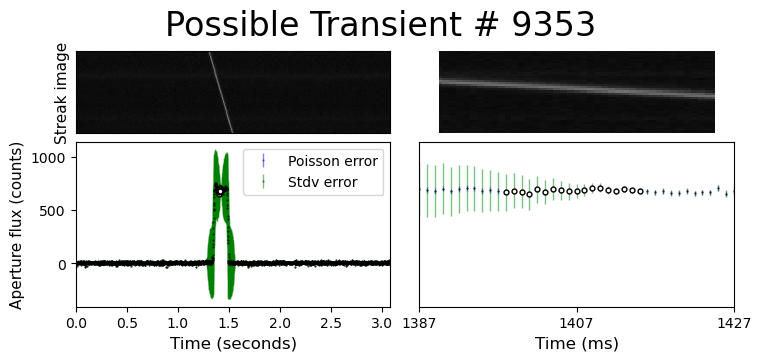

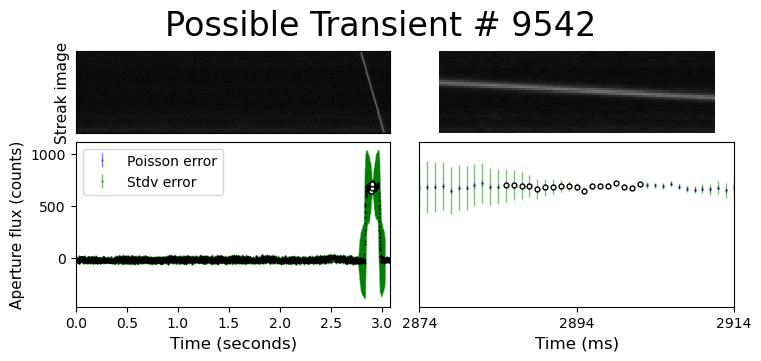

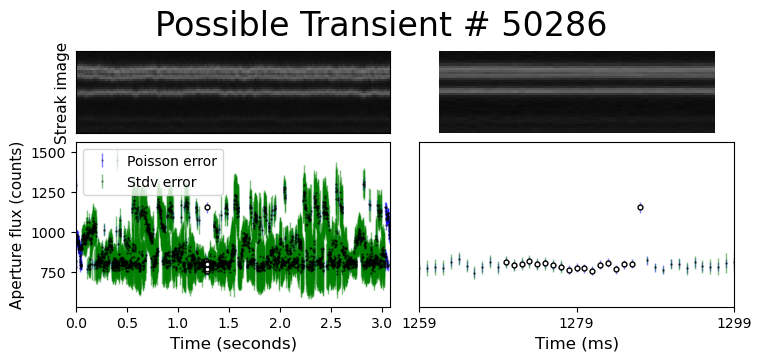

...

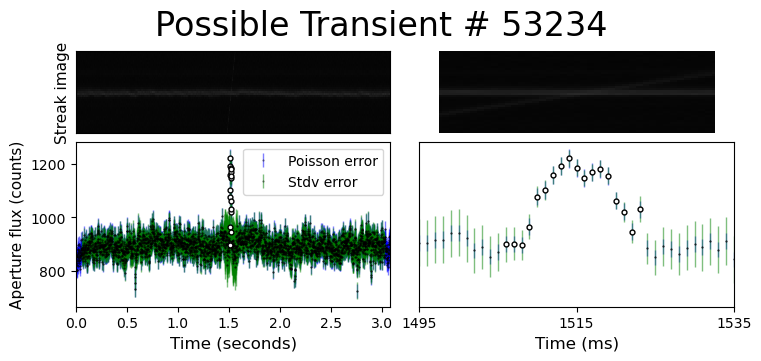

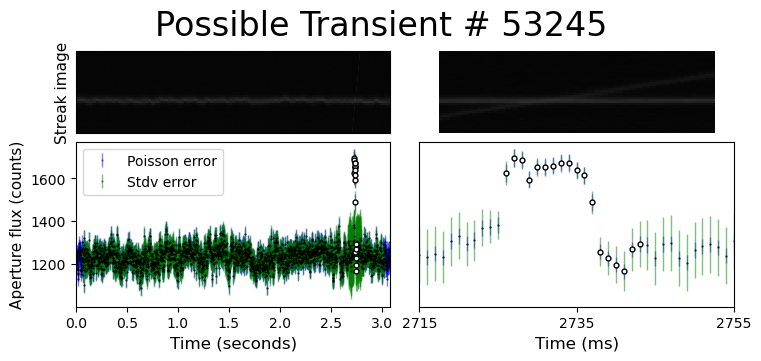

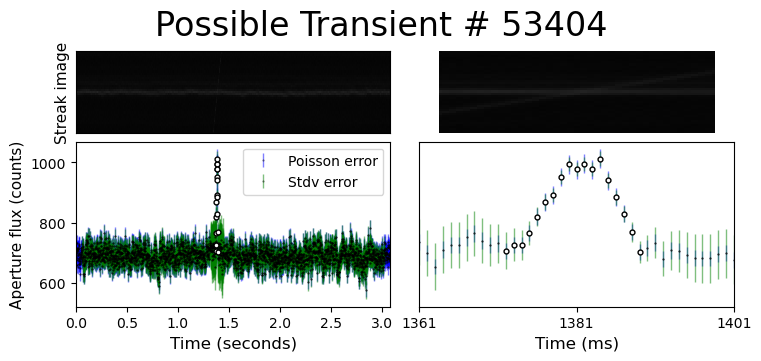

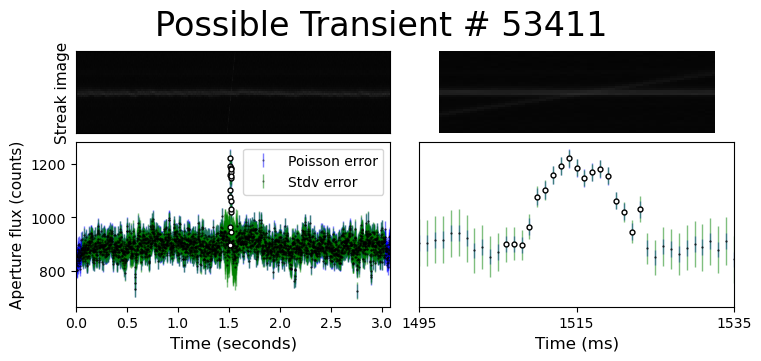

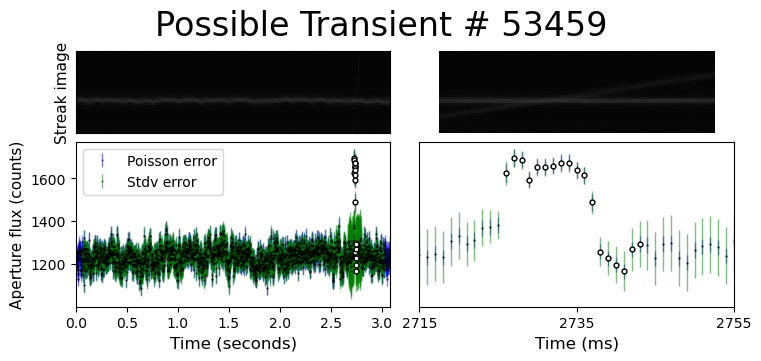

In [45]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 8859, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 8920, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 9353, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 9542, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 50286, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 50390, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 53231, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 53234, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 53245, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 53404, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 53411, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 53459, '1020', 2, True)



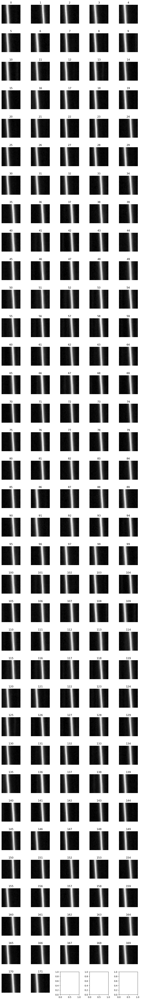

In [35]:
rff.inspect_df_with_quadrant(concatenated_df_snr[concatenated_df_snr['snr_max']>40], '1020')

In [8]:
df_lessthan8 = concatenated_df_snr[np.abs(concatenated_df_snr['snr_max'])<8]

In [9]:
df_lessthan8[np.abs(df_lessthan8['snr_max'])>7]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
25164,104,104,221,221,ztf_20221020157697_000640_zi_c16_x_0009.,neg,2644.425532,732.936170,47.0,2,14.604728,4.895341,7.467139,3.664021
25286,226,226,464,464,ztf_20221020157697_000640_zi_c16_x_0009.,both,2644.425532,732.936170,47.0,2,14.604728,4.895341,7.467139,3.664021
107097,27,27,272,272,ztf_20221020148032_000686_zg_c16_x_0001.,pos,2524.666667,661.266667,15.0,2,5.355525,5.936502,7.108738,-0.225223
107403,334,334,959,959,ztf_20221020148032_000686_zg_c16_x_0001.,both,2524.666667,661.266667,15.0,2,5.355525,5.936502,7.108738,-0.225223
124175,31,31,225,225,ztf_20221020157697_000640_zi_c09_x_0025.,pos,1026.375000,1751.437500,48.0,4,10.876323,7.382644,7.382644,-2.223329
124275,131,131,657,657,ztf_20221020157697_000640_zi_c09_x_0025.,neg,1034.733333,1751.866667,30.0,4,10.876323,-0.207415,7.738497,-2.378934
124445,301,301,1129,1129,ztf_20221020157697_000640_zi_c09_x_0025.,both,1026.375000,1751.437500,48.0,4,10.876323,7.382644,7.382644,-2.223329
124446,302,302,1132,1132,ztf_20221020157697_000640_zi_c09_x_0025.,both,1034.733333,1751.866667,30.0,4,10.876323,-0.207415,7.738497,-2.378934
145406,4,4,14,14,ztf_20221020163819_000640_zg_c06_x_0025.,pos,2001.666667,1068.866667,15.0,3,5.146079,-0.191538,7.179645,-1.354989
145436,34,34,142,142,ztf_20221020163819_000640_zg_c06_x_0025.,both,2001.666667,1068.866667,15.0,3,5.146079,-0.191538,7.179645,-1.354989


In [ ]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 6440, '1020', 2, True)

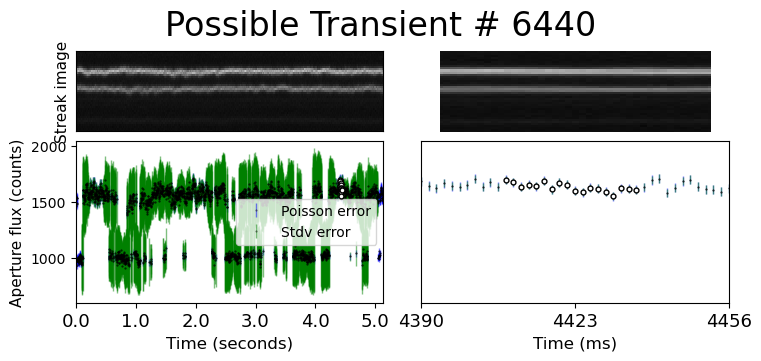

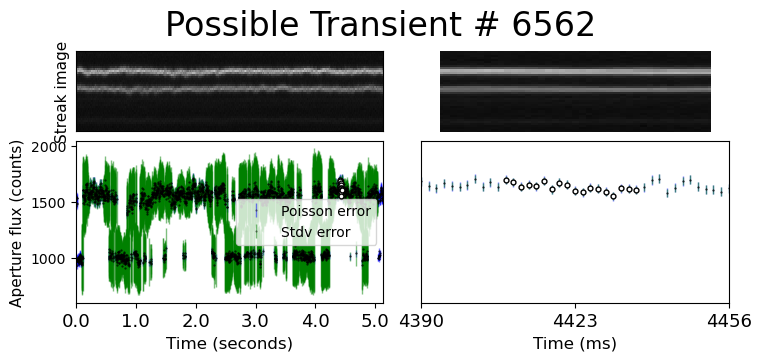

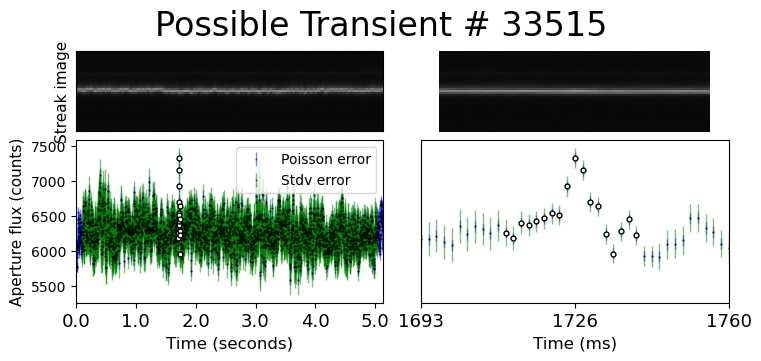

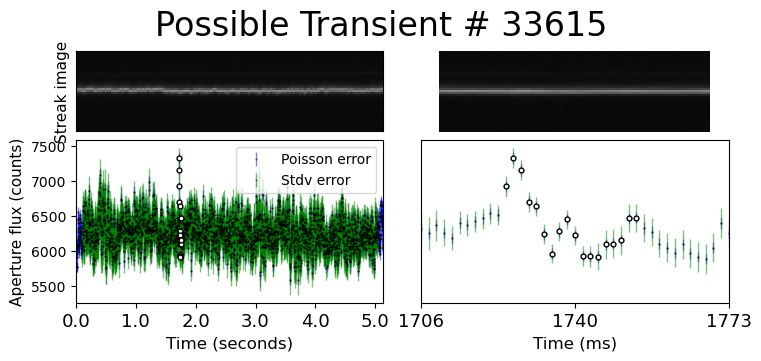

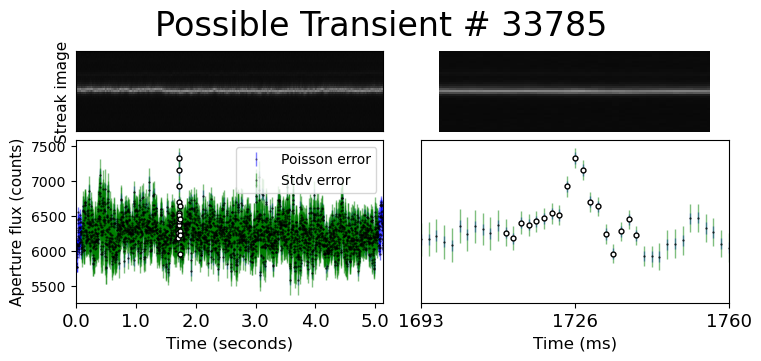

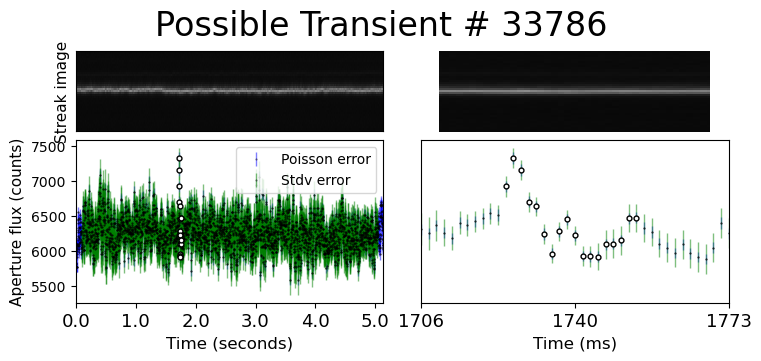

In [129]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 6440, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 6562, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 33515, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 33615, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 33785, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 33786, '1020', 2, True)

In [130]:
df_lessthan8

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,0,1,1,ztf_20221020163819_000640_zg_c11_x_0020.,pos,809.500000,2912.333333,6.0,4,12.262497,2.618857,2.618857,-1.632732
1,1,1,2,2,ztf_20221020163819_000640_zg_c11_x_0020.,pos,896.200000,1361.600000,5.0,4,11.266582,2.244716,2.450370,-2.741039
2,2,2,5,5,ztf_20221020163819_000640_zg_c11_x_0020.,pos,1285.000000,2910.000000,5.0,4,15.076541,2.094160,2.413203,-1.461193
3,3,3,7,7,ztf_20221020163819_000640_zg_c11_x_0020.,pos,1472.800000,2912.400000,5.0,4,17.907404,2.744043,3.056441,-1.015130
4,4,4,10,10,ztf_20221020163819_000640_zg_c11_x_0020.,pos,1728.800000,2912.400000,5.0,4,13.927176,1.458792,3.037962,-2.127889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161314,263,263,551,551,ztf_20221020297847_000449_zr_c14_x_0026.,both,2923.142857,1320.428571,7.0,4,9.755448,0.476716,1.637385,-1.839140
161315,264,264,552,552,ztf_20221020297847_000449_zr_c14_x_0026.,both,2937.153846,1320.692308,13.0,4,11.997117,0.194553,0.760646,-1.656184
161316,265,265,554,554,ztf_20221020297847_000449_zr_c14_x_0026.,both,2951.500000,1321.416667,12.0,4,14.919274,-0.671413,0.720585,-1.495678
161317,266,266,555,555,ztf_20221020297847_000449_zr_c14_x_0026.,both,2952.000000,1326.000000,9.0,4,14.998910,-1.493181,0.719382,-1.493181


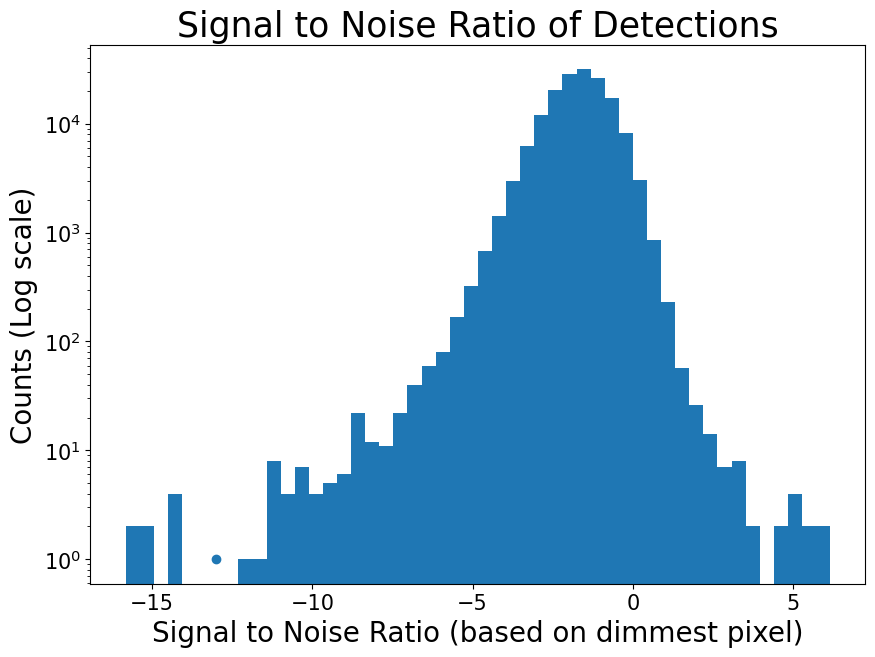

In [141]:
#above is the best we've got for that
#now let's look at negative!
plt.hist(df_lessthan8['snr_min'], bins=50)
plt.yscale('log')
plt.title('Signal to Noise Ratio of Detections', fontsize=25)
plt.ylabel('Counts (Log scale)', fontsize=20)
plt.xlabel("Signal to Noise Ratio (based on dimmest pixel)", fontsize=20)
# plt.xlim(0,20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# plt.scatter(-13, 1)

In [135]:
df_lessthan8[df_lessthan8['snr_min']<-13]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
6368,32,32,104,104,ztf_20221020157697_000640_zi_c16_x_0009.,neg,883.0,733.000,5.0,2,7.697234,-14.214947,0.886260,-15.829136
6487,151,151,330,330,ztf_20221020157697_000640_zi_c16_x_0009.,both,883.0,733.000,5.0,2,7.697234,-14.214947,0.886260,-15.829136
6728,13,13,50,50,ztf_20221020157697_000640_zi_c16_x_0000.,neg,98.5,733.000,8.0,2,9.853301,-2.795770,0.808436,-14.083176
6860,145,145,253,253,ztf_20221020157697_000640_zi_c16_x_0000.,both,98.5,733.000,8.0,2,9.853301,-2.795770,0.808436,-14.083176
19722,110,110,210,210,ztf_20221020154120_000640_zi_c16_x_0004.,neg,2153.1,732.100,10.0,2,14.554659,-0.534448,1.222541,-15.101740
19865,253,253,488,488,ztf_20221020154120_000640_zi_c16_x_0004.,both,2153.1,732.100,10.0,2,14.554659,-0.534448,1.222541,-15.101740
49792,142,142,273,273,ztf_20221020154120_000640_zi_c16_x_0019.,neg,2718.0,732.625,8.0,2,11.786573,0.934524,1.285109,-14.408841
49942,292,292,571,571,ztf_20221020154120_000640_zi_c16_x_0019.,both,2718.0,732.625,8.0,2,11.786573,0.934524,1.285109,-14.408841


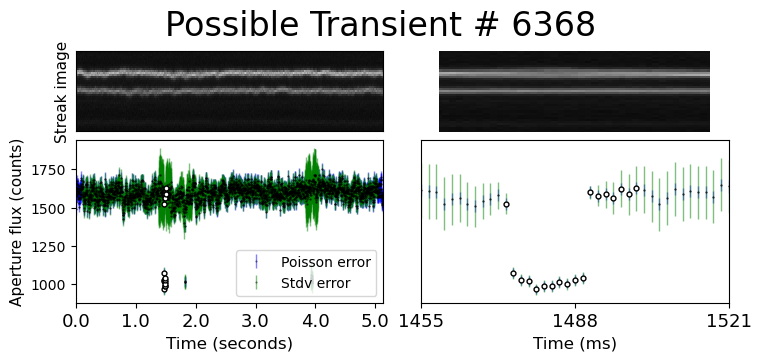

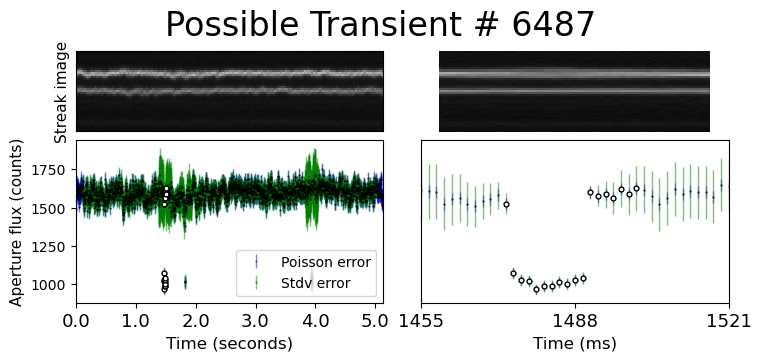

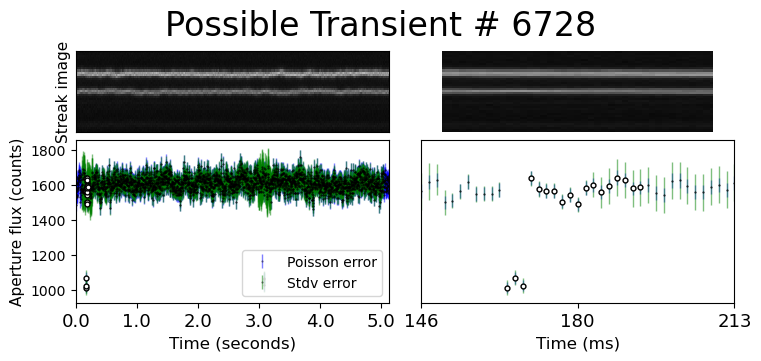

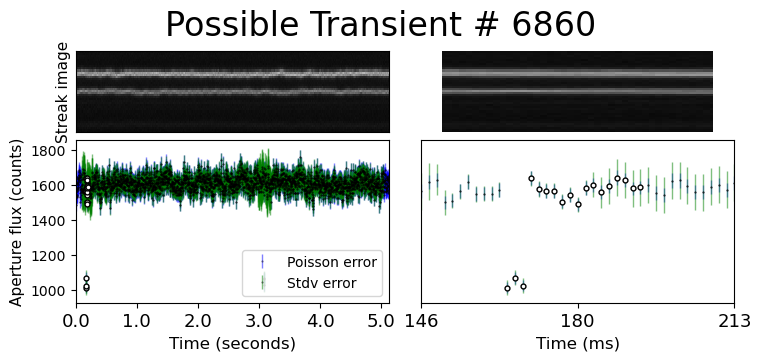

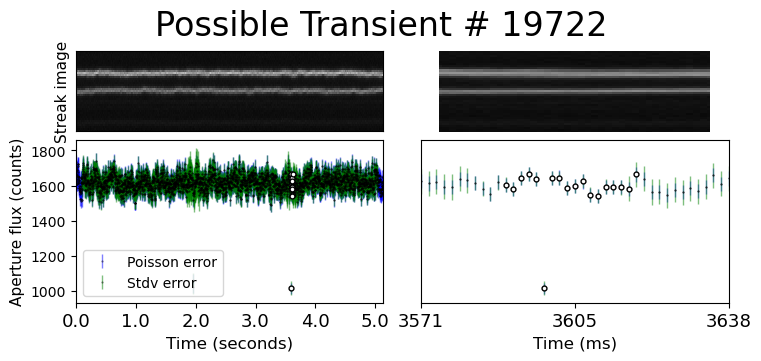

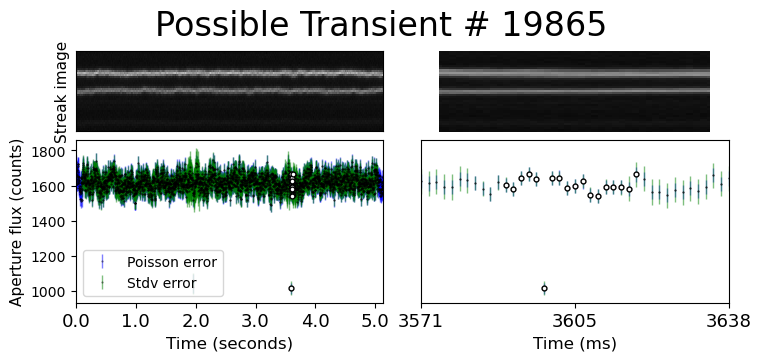

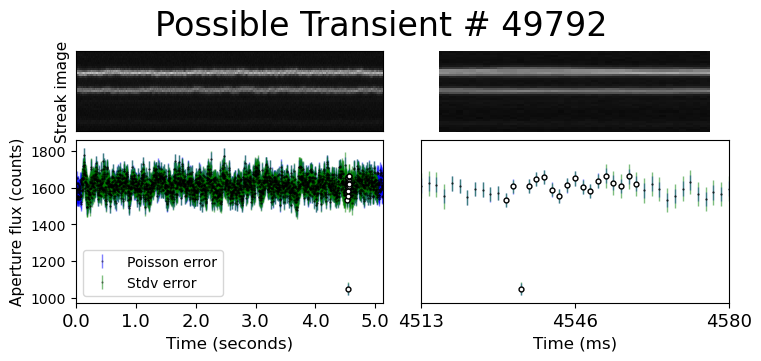

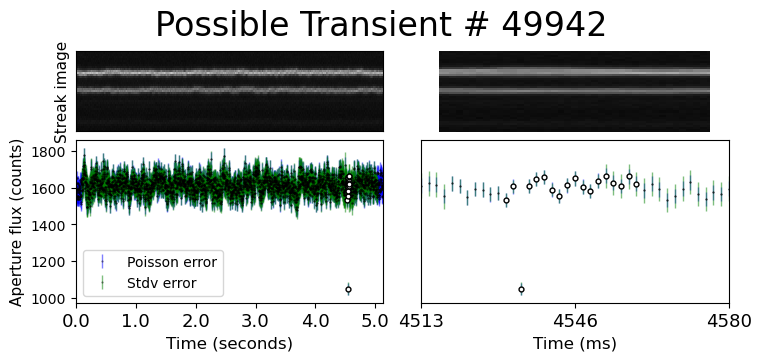

In [136]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 6368, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 6487, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 6728, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 6860, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 19722, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 19865, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 49792, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 49942, '1020', 2, True)

In [137]:
df_lessthan8[df_lessthan8['snr_min']>5]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
8874,64,64,170,170,ztf_20221020148032_000686_zg_c16_x_0014.,pos,1526.0,754.545455,11.0,4,5.588866,6.436785,6.881999,6.160150
9401,591,591,1255,1255,ztf_20221020148032_000686_zg_c16_x_0014.,both,1526.0,754.545455,11.0,4,5.588866,6.436785,6.881999,6.160150
72647,180,180,367,367,ztf_20221020148032_000686_zg_c09_x_0007.,neg,1511.0,161.500000,10.0,4,20.154459,6.154642,6.574654,5.686168
72917,450,450,881,881,ztf_20221020148032_000686_zg_c09_x_0007.,both,1511.0,161.500000,10.0,4,20.154459,6.154642,6.574654,5.686168


/home/3155/review_findings_functions.py:1137: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


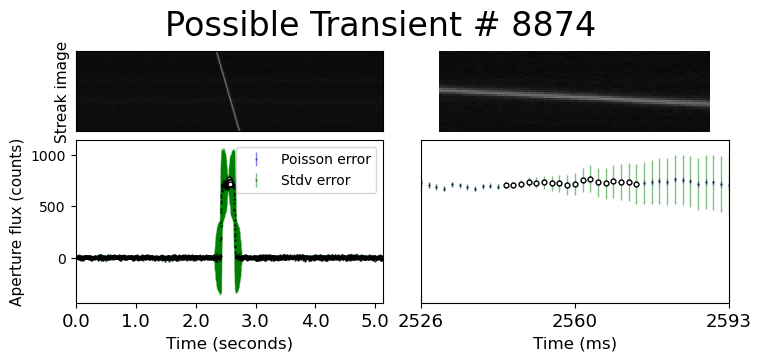

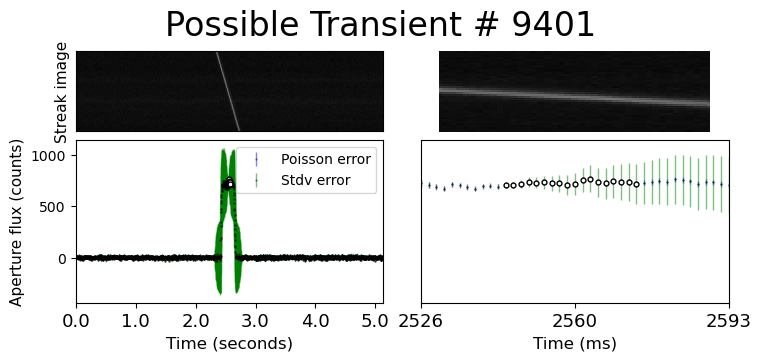

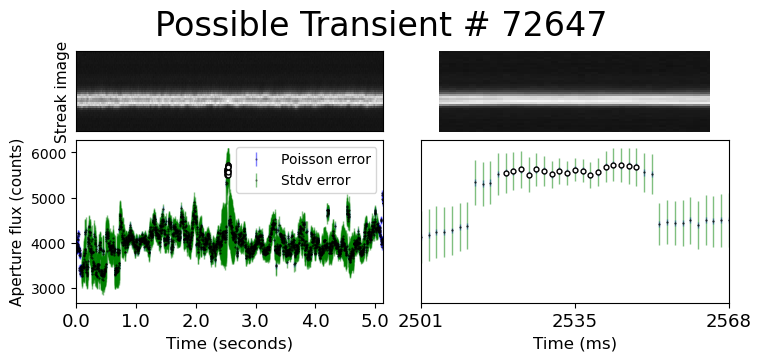

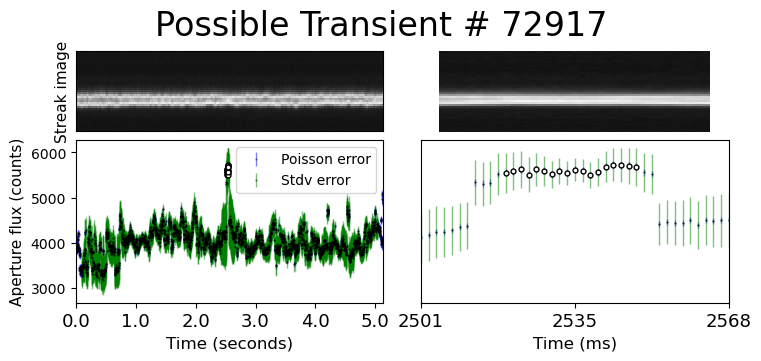

In [138]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 8874, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 9401, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 72647, '1020', 2, True)
rff.plot_time_series_again_aperture(concatenated_df_snr, 72917, '1020', 2, True)

In [143]:
df_andgreaterthanneg13 = df_lessthan8[df_lessthan8['snr_min']>-13]

In [145]:
df_andgreaterthanneg13[df_andgreaterthanneg13['snr_min']<-10].index

Int64Index([  7657,   7808,  78009,  78022, 107248, 107359, 113954, 113970,
            114006, 114007, 114061, 114078, 114104, 114105, 140942, 141058,
            143486, 143590, 143732, 149665, 149797],
           dtype='int64')

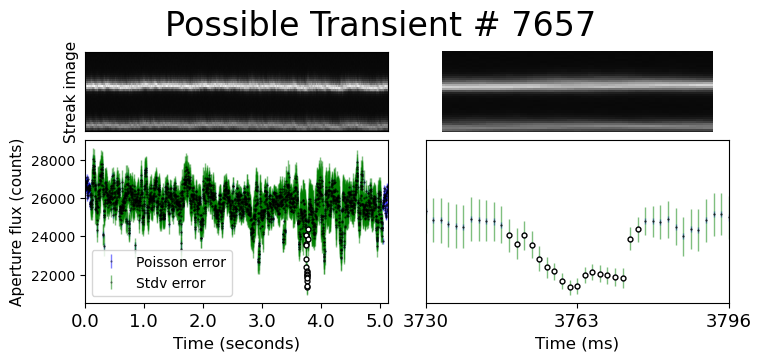

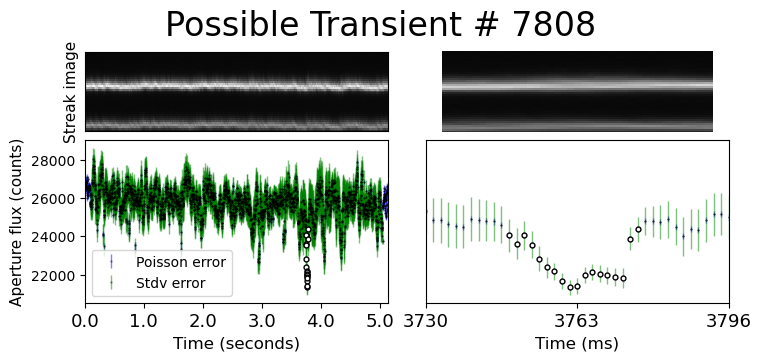

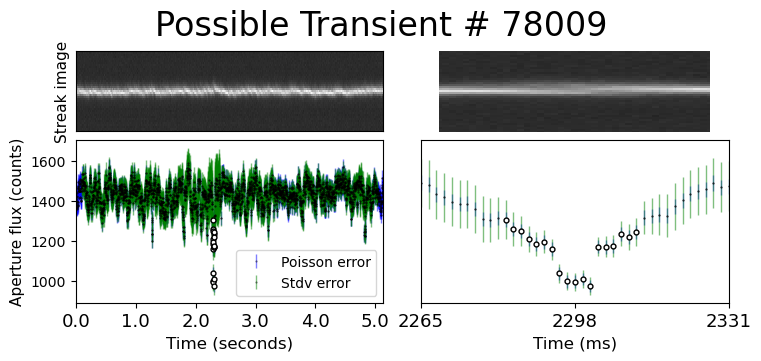

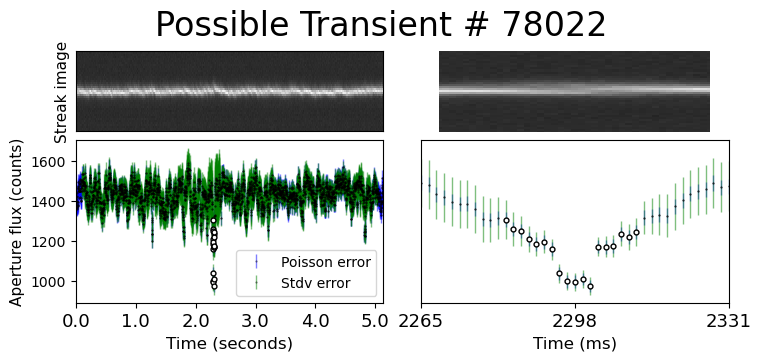

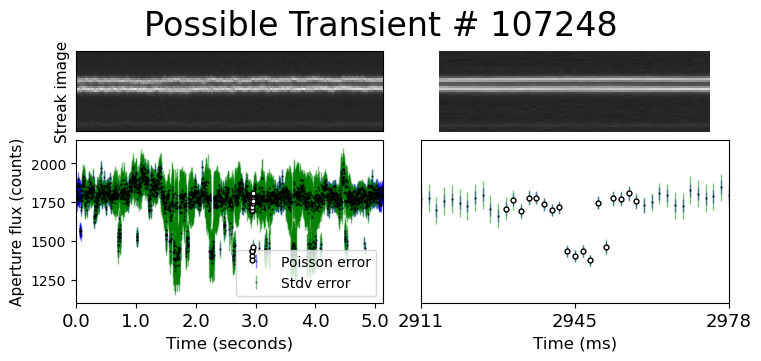

...

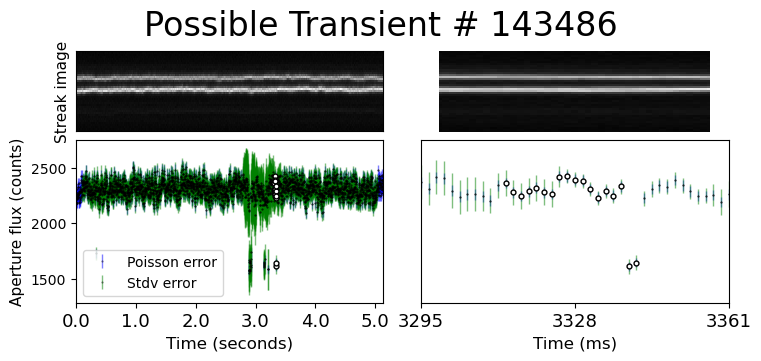

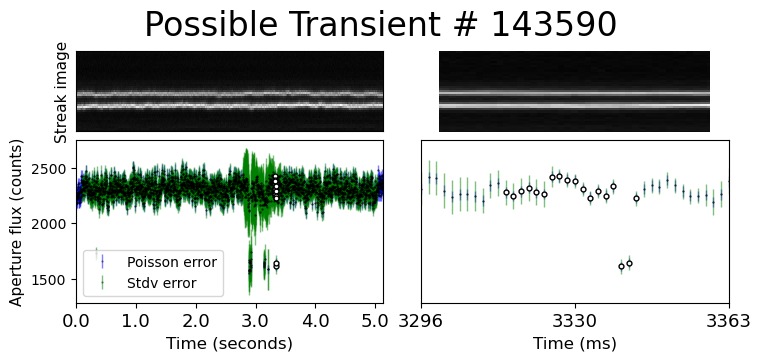

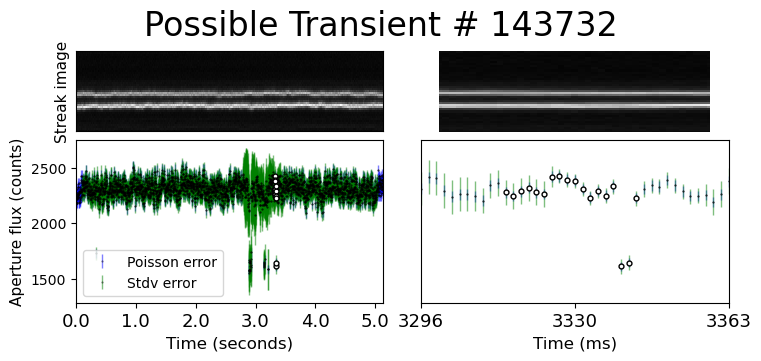

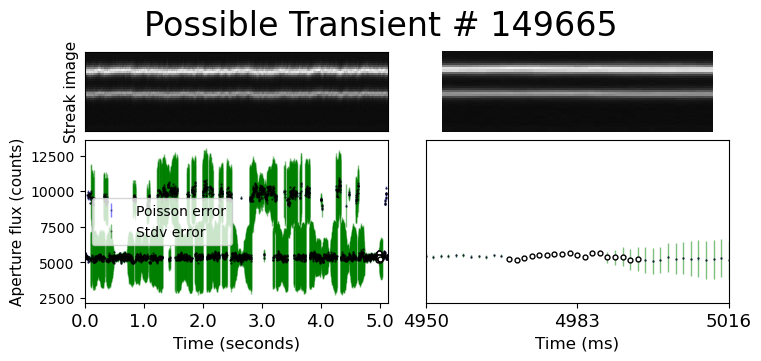

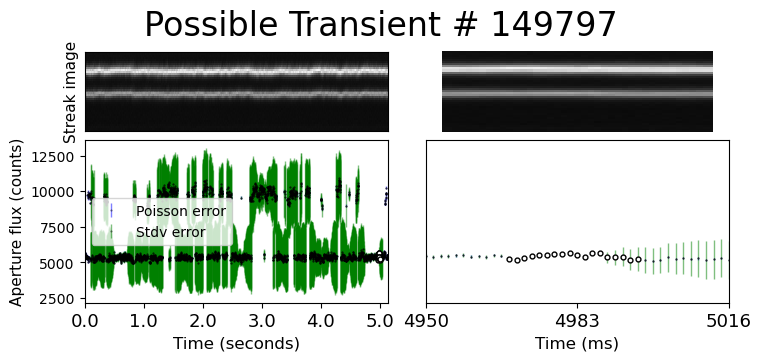

In [146]:
# df_andgreaterthanneg13[df_andgreaterthanneg13['snr_min']<-10]

for index in df_andgreaterthanneg13[df_andgreaterthanneg13['snr_min']<-10].index:
    rff.plot_time_series_again_aperture(concatenated_df_snr, index, '1020', 2, True)


In [154]:
concatenated_df_snr.loc[33785]

Unnamed: 0.3                                           301
Unnamed: 0.2                                           301
Unnamed: 0.1                                          1129
Unnamed: 0                                            1129
filename          ztf_20221020157697_000640_zi_c09_x_0025.
type                                                  both
row_from_nn                                       1026.375
col_from_nn                                      1751.4375
detection_size                                        48.0
quadrant                                                 4
sobel_ratio                                      10.876323
snr_center                                        7.382644
snr_max                                           7.382644
snr_min                                          -2.223329
Name: 33785, dtype: object

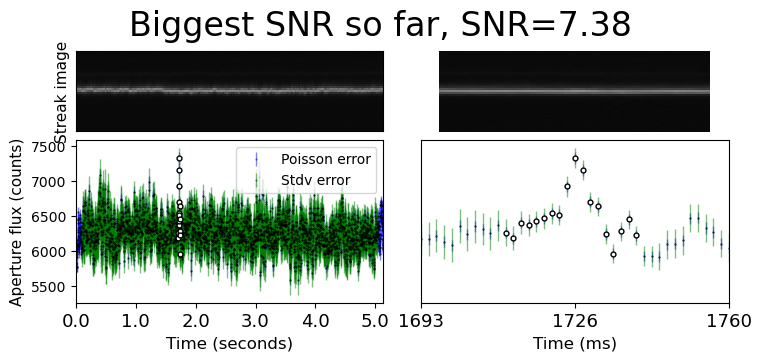

In [156]:
rff.plot_time_series_again_aperture(concatenated_df_snr, 33785, '1020', 2, True, title='Biggest SNR so far, SNR=7.38')

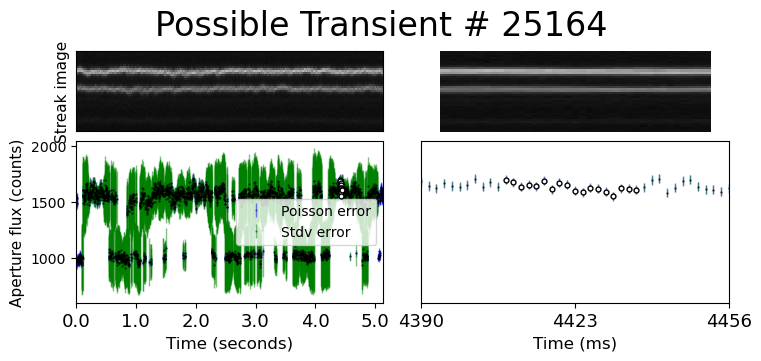

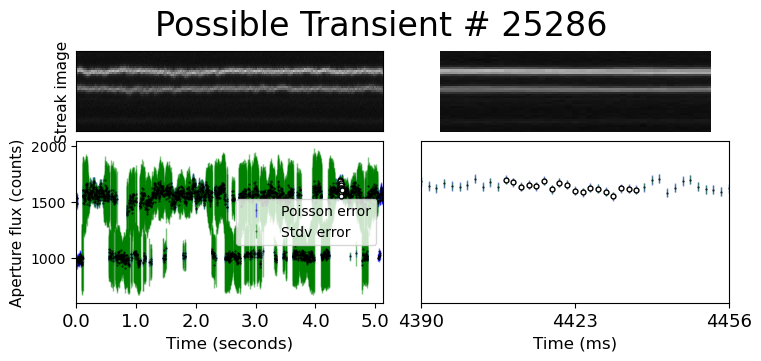

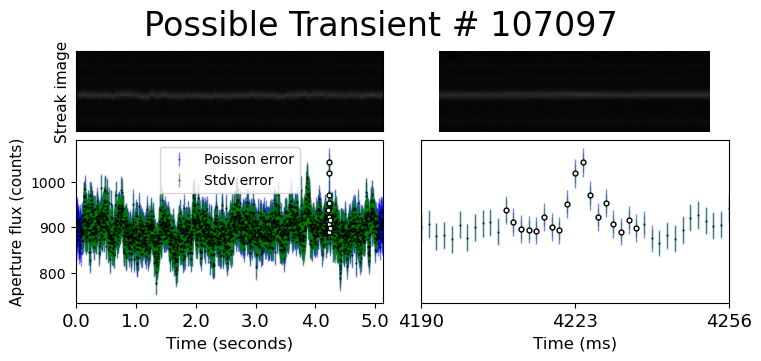

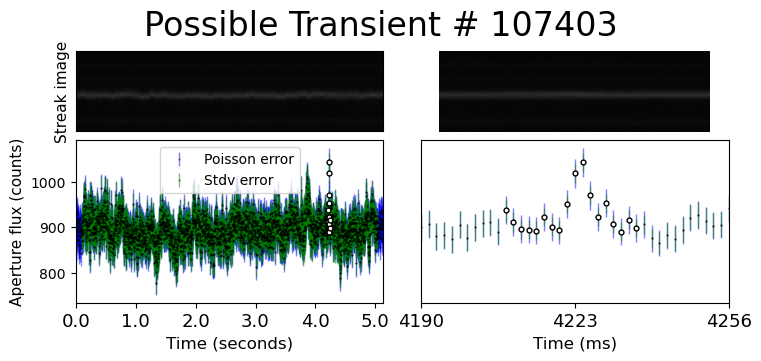

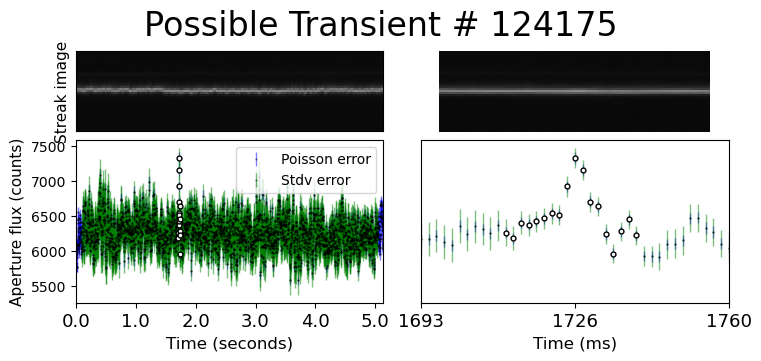

...

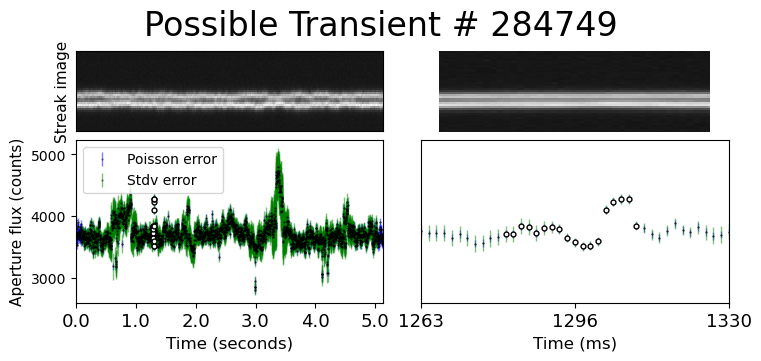

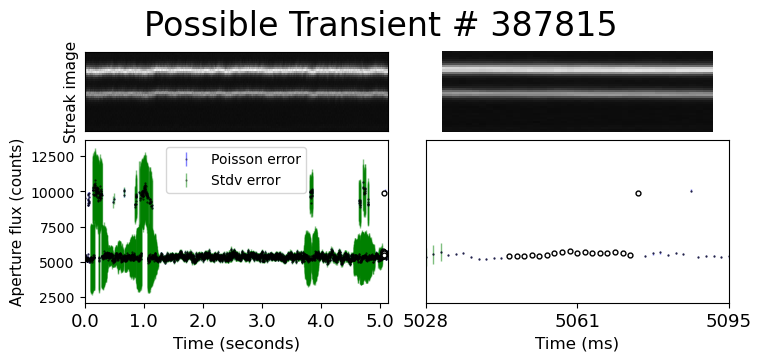

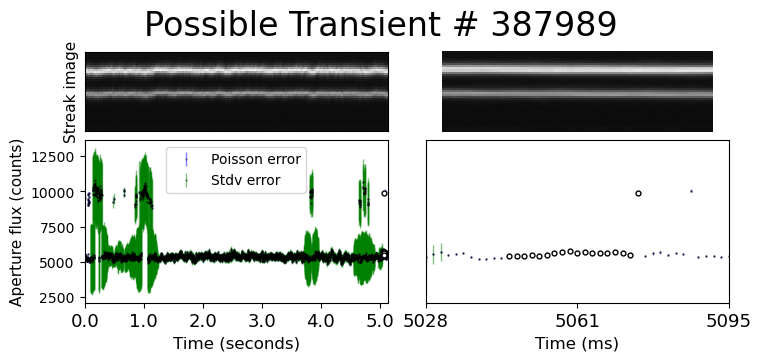

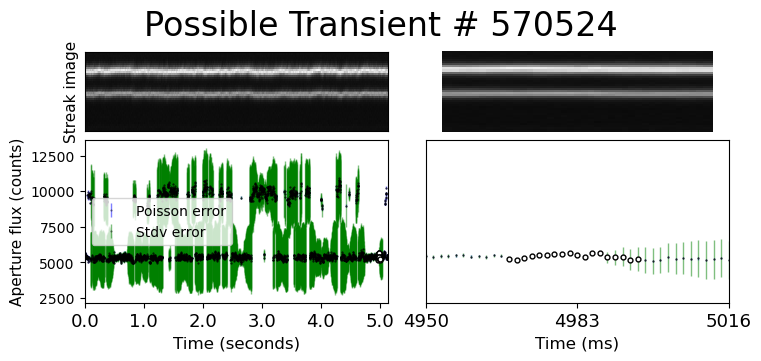

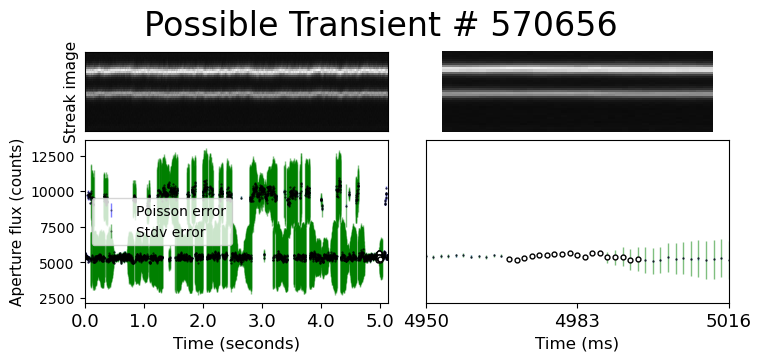

In [10]:
# df_andgreaterthanneg13[df_andgreaterthanneg13['snr_min']<-10]

for index in df_lessthan8[np.abs(df_lessthan8['snr_max'])>7].index:
    rff.plot_time_series_again_aperture(concatenated_df_snr, index, '1020', 2, True)


In [44]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

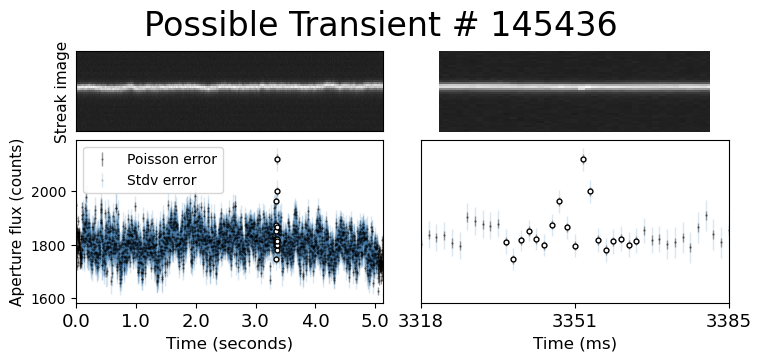

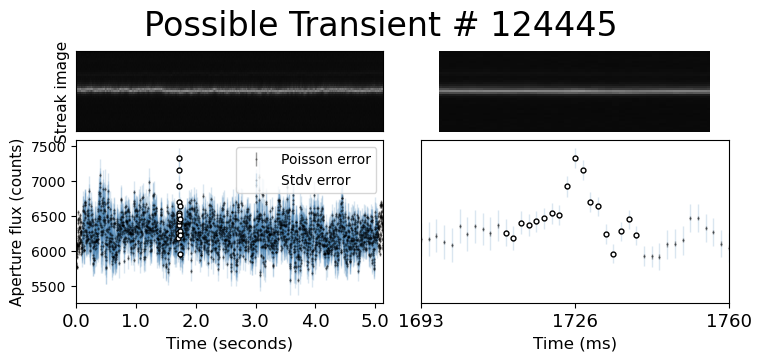

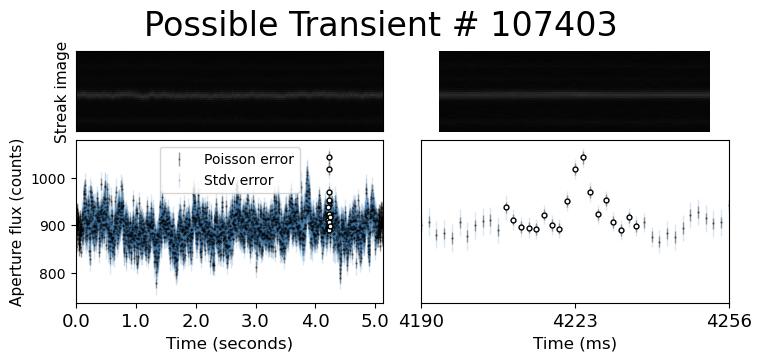

In [45]:
indices = [145436, 124445, 107403]
    
for index in indices:
    rff.plot_time_series_again_aperture(concatenated_df_snr, index, '1020', 2, True)


In [12]:
tot_107403, maxcols = rff.get_tot(df=concatenated_df_snr, index=107403, direcname='1020', half_aperture=2, tracking=True)

In [14]:
from scipy.fft import rfft, irfft, rfftfreq

In [22]:
def get_rfft_sq(index, direcname, df, half_aperture, tracking, plot=False, name="concatenated_df_snr"):
    wideval = 2
    fname = df.iloc[index]["filename"]+"fits.fz"
    row = int(df.iloc[index]["row_from_nn"])+10
    col = int(df.iloc[index]["col_from_nn"])+10
    quad = int(df.iloc[index]["quadrant"])
    fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
    path = fpath+fname
    hdul=fits.open(path)
    image = hdul[quad].data
    column=col
    # image = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    
    
    background = rff.get_image_background(image)

   
    imagenobackground = image - np.full(np.shape(image),background)

    tot, maxcols = rff.get_tot(df, index, direcname, half_aperture, tracking)
    
   

    sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
    Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
    N = len(tot)
    freqs = np.fft.rfftfreq(N, d=1/Fs)
    
    pixel_to_ms_factor = 1 / 0.6
    freqs_ms = freqs / pixel_to_ms_factor

    if plot==True:
        plt.plot(freqs_ms[1:], sqfft)
        plt.ylabel("Power")
        plt.xlabel("Frequency (KHz)") #cycles per millisecond
        plt.title("RFFT^2 of streak "+str(index)+" from df "+str(name))
        # plt.yscale("log")
    return sqfft, freqs_ms

In [15]:
Fs = 1  # Assuming pixel as unit for FFT frequency calculation
N = len(tot_107403)
fft_vals = rfft(tot_107403)
freqs = rfftfreq(N, d=1/Fs)

# Step 2: Convert frequencies to cycles per millisecond (mHz)
pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms

(array([4.14755114e+07, 1.44287566e+07, 3.79306351e+06, ...,
        7.78739625e+05, 9.60327353e+05, 2.65896775e+04]),
 array([0.00000000e+00, 1.94805195e-04, 3.89610390e-04, ...,
        2.99610390e-01, 2.99805195e-01, 3.00000000e-01]))

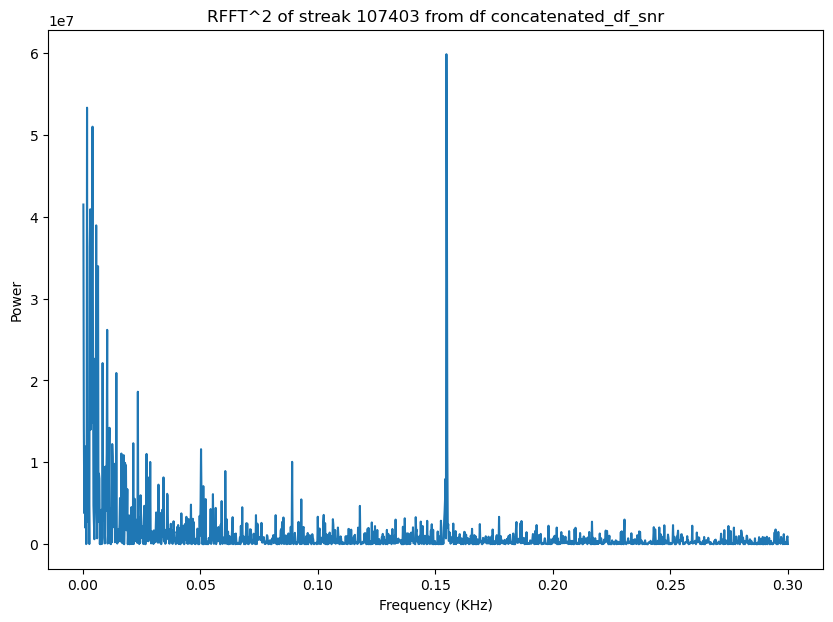

In [23]:
get_rfft_sq(107403, '1020', concatenated_df_snr, half_aperture=2, tracking=True, plot=True, name="concatenated_df_snr")

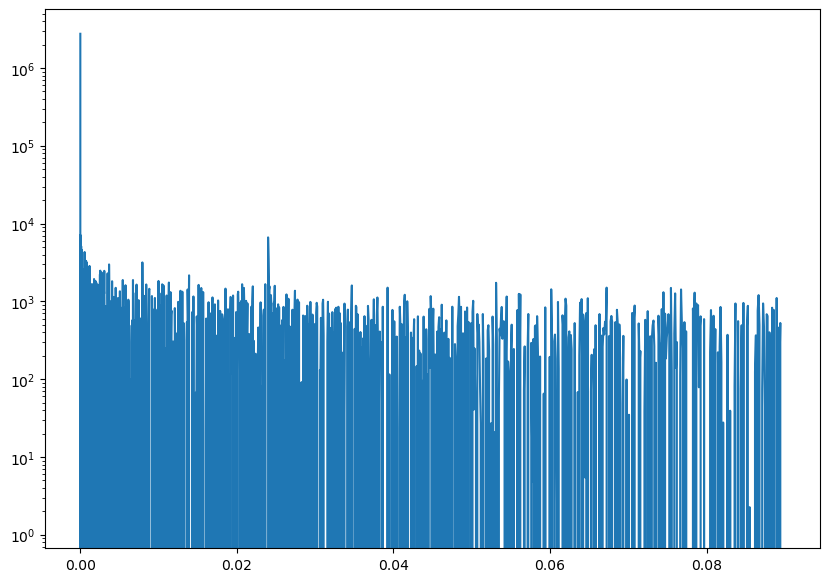

In [18]:
plt.plot(np.square(freqs_ms), fft_vals)
plt.yscale('log')

In [12]:
concatenated_df_snr[np.abs(concatenated_df_snr['snr_min'])<8]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,0,3,3,ztf_20221020297847_000449_zr_c05_x_0006.,pos,627.166667,559.333333,6.0,4,12.891250,1.303873,1.792471,-1.921662
1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8.0,4,12.620198,3.551599,3.661652,-3.093721
2,2,2,8,8,ztf_20221020297847_000449_zr_c05_x_0006.,pos,1834.833333,560.916667,12.0,4,7.786941,2.971391,2.971391,-1.201024
3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12.0,4,9.809223,3.095683,3.140310,-0.995967
4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,14.0,4,12.620198,-1.530615,3.552551,-3.001541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610898,263,263,551,551,ztf_20221020297847_000449_zr_c14_x_0026.,both,2923.142857,1320.428571,7.0,4,9.755448,0.476716,1.637385,-1.839140
610899,264,264,552,552,ztf_20221020297847_000449_zr_c14_x_0026.,both,2937.153846,1320.692308,13.0,4,11.997117,0.194553,0.760646,-1.656184
610900,265,265,554,554,ztf_20221020297847_000449_zr_c14_x_0026.,both,2951.500000,1321.416667,12.0,4,14.919274,-0.671413,0.720585,-1.495678
610901,266,266,555,555,ztf_20221020297847_000449_zr_c14_x_0026.,both,2952.000000,1326.000000,9.0,4,14.998910,-1.493181,0.719382,-1.493181


In [15]:
len(concatenated_df_snr)

610903

In [16]:
len(df_lessthan13_pos)

610712

In [14]:
df_lessthan13_pos = concatenated_df_snr[np.abs(concatenated_df_snr['snr_max'])<13]

In [17]:
df_lessthan13 = df_lessthan13_pos[np.abs(df_lessthan13_pos['snr_min'])<13]

In [18]:
len(df_lessthan13)

610673

In [ ]:
df_lessthan13 = df_lessthan8[df_lessthan8[

In [19]:
df_lessthan13.to_csv('/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/df_lessthan13')